<div class="alert alert-info">
<font size="5"><b>Комментарий ревьюера</b></font>

Привет Мария! Меня зовут Марат, и я буду твоим ревьюером. Спешу сообщить что все ключевые этапы в работе выполнены,  с задачей тебе удалось справиться. По поводу обращения - в IT сфере принято общаться на «ты» :) Но, если привычней на «вы», дай знать. Как ревьюера моя задача помочь тебе в развитии, дав хорошие советы. Я внимательно посмотрю твой код, ознакомлюсь с твоими выводами и оставлю комментарии. Где то могу предложить небольшие исправление в коде, но ненавязчиво. Где потребуются уточнения, я оставлю много наводящих вопросов. Они помогут тебя с поиском верного решения.

Все мои комментарии размечены по цветам, для лучшего восприятия. 
    
<div class="alert alert-success">Зеленым цветом и словом «Успех» отмечены особо удачные и элегантные решения, которыми ты можешь гордиться. </div>
        
<div class="alert alert-warning">Желтым и значком словом «Совет», помечены решения у которых есть альтернативные решения, более оптимальные. Ты можешь найти их сразу и доработать проект, или отложить это на потом, для будущих проектах. Проект будет принят и без их доработки. </div>
        
<div class="alert alert-danger"> Красным цветом и значком словом «Ошибка» помечу твои решения, на которые стоит обратить внимание прежде всего. После их доработки проект будет принят. </div>
        
Залог успеха - работа сообща, взаимное уважение и работа в диалоге. Поэтому, помечай свои ответные комментарии на мои реплики заметным цветом или курсивом, так мне будет легче их отслеживать. Пожалуйста, не изменяй и не удаляй мои комментарии. Все это поможет выполнить повторную проверку быстрей.

</div>

# Рекомендация тарифов

В вашем распоряжении данные о поведении клиентов, которые уже перешли на эти тарифы (из проекта курса «Статистический анализ данных»). Нужно построить модель для задачи классификации, которая выберет подходящий тариф. Предобработка данных не понадобится — вы её уже сделали.

Постройте модель с максимально большим значением *accuracy*. Чтобы сдать проект успешно, нужно довести долю правильных ответов по крайней мере до 0.75. Проверьте *accuracy* на тестовой выборке самостоятельно.

<div class="alert alert-success">
<font size="5"><b>Комментарий ревьюера</b></font>

Успех:


Вступление в работу очень важно, так человек, который смотрит твой проект (и на работе в том числе) будет сразу введен в курс дела.





</div>

## Откройте и изучите файл

In [46]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
import matplotlib.pyplot as plt


In [47]:
data = pd.read_csv('/datasets/users_behavior.csv')
data.head()

,calls,minutes,messages,mb_used,is_ultra
0,40.0,311.90,83.0,19915.42,0
1,85.0,516.75,56.0,22696.96,0
2,77.0,467.66,86.0,21060.45,0
3,106.0,745.53,81.0,8437.39,1
4,66.0,418.74,1.0,14502.75,0


<div class="alert alert-success">
<font size="5"><b>Комментарий ревьюера</b></font>

Успех:

Собираем все импорты в верхней части, чтобы легче было ориентироваться и добавлять новые по необходимости. 


<div class="alert alert-warning">

Совет:     
    
- Все-таки стоит импорт библиотек и выгрузку данных разнести в разные ячейки, так стилистически более правильно.


- кстати есть рекомендации PEP-8 при написании кода, в том числе и для импортов. Если интересно можешь почитать [тут](https://pythonworld.ru/osnovy/pep-8-rukovodstvo-po-napisaniyu-koda-na-python.html) 


Импортируем необходимые библиотеки и сохраняем файл в переменную.

In [48]:
data.info()
data.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3214 entries, 0 to 3213
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   calls     3214 non-null   float64
 1   minutes   3214 non-null   float64
 2   messages  3214 non-null   float64
 3   mb_used   3214 non-null   float64
 4   is_ultra  3214 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 125.7 KB


calls       0
minutes     0
messages    0
mb_used     0
is_ultra    0
dtype: int64

<AxesSubplot:>

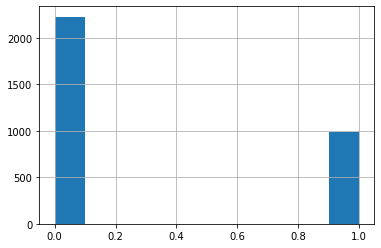

In [49]:
data['is_ultra'].hist()

<div class="alert alert-success">
<font size="5"><b>Комментарий ревьюераV2</b></font>

Успех:

    
Добавила EDA    
    
</div>


Датасет относительно небольшой, всего около трех тысяч строк и 5 колонок. Это может существенно влиять на адекватность работы обученной модели. Все данные - приемлимых типов, пропуски отсутствуют. Таргеты довольно не сбалансированы, однако соотношение приемлимо. Тариф ультра встречается больше чем в 2 раза чаще, чем другой.

<div class="alert alert-danger">
<font size="5"><b>Комментарий ревьюера</b></font>

Ошибка: 
    
Небольшой EDA не помешает, так как это аналитический проект. В данном проекте датасет "чистенький", но кто знает какой датасет нас будет ждать завтра, надо быть готовым. Хотя бы info() и вывод по увиденному.
Плюс проверить датасет на сбалансированность таргетов, это бы дало информацию для train_test_split и помогло решить бонусное задание сразу. 


</div>


## Разбейте данные на выборки

In [50]:
features = data.drop(['is_ultra'], axis=1)
target = data['is_ultra'] 

features_train_valid, features_test, target_train_valid, target_test = train_test_split(
    features, target, test_size=0.2, random_state=12345, stratify=target)

features_train, features_valid, target_train, target_valid = train_test_split(
    features_train_valid, target_train_valid, test_size=0.25, random_state=12345, stratify=target_train_valid)

Определяем параметры и признак, по которому будем обучать модель классификации. Используя train_test_split дважды, разделяем данные на обучающую, валидационную и тестовую выборки в соотношении 3:1:1.

In [51]:
print(features_test.shape)
print(target_test.shape)
print(features_train.shape)
print(target_train.shape)
print(features_valid.shape)
print(target_valid.shape)

(643, 4)
(643,)
(1928, 4)
(1928,)
(643, 4)
(643,)


<div class="alert alert-danger">
<font size="5"><b>Комментарий ревьюера</b></font>

Ошибка:

    
У тебя 3 train_test_split, хватиает 2   

<div class="alert alert-warning">



Совет: 


- Обрати внимание на аргумент stratify, он позволит сохранить изначальное распределение таргетов во всех новых датасетах.  Существующий дисбаланс никуда не денется, но в каждом датасете он будет одинаковым


- После разбиения лучше перестраховаться и использовать .shape, для контроля за корректностью разбиения





</div>





<div class="alert alert-success">
<font size="5"><b>Комментарий ревьюераV2</b></font>

Успех:

Использовала все советы    

</div>


## Исследуйте модели

In [52]:
best_model = None
best_result = 0
best_depth = 0
dt_scores = []
for depth in range(1, 10):
    model = DecisionTreeClassifier(random_state=12345, max_depth=depth) 
    model.fit(features_train, target_train) 
    predictions_tree_valid = model.predict(features_valid)
    result = accuracy_score(target_valid, predictions_tree_valid)
    dt_scores.append(result)
    if result > best_result:
        best_model_dt = model
        best_result = result
        best_depth = depth
        
print(f'The best depth is {best_depth}, and the best result is {best_result}')

The best depth is 5, and the best result is 0.8164852255054432


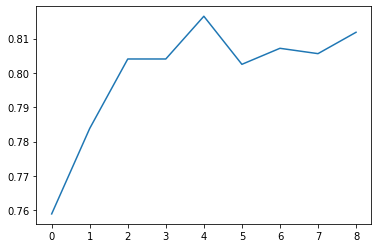

In [53]:
plt.plot(list(range(len(dt_scores))), dt_scores)
plt.show();




<div class="alert alert-warning">
<font size="5"><b>Комментарий ревьюераV2</b></font>

Совет:

Здорово!  
    
- Но он получился не таким информативным как мог бы быть. Во-первых стоит сюда добавить метрику и по train (так принято для отслеживания переобучения):
    
    
    Добавляешь (схема):


        predictions_train = model.predict(features_train)
        result_train = accuracy_score(target_train, predictions_train)


    а теперь собираешь в цикле  result_train и result в списки, и строишь по ним обычный график plt.plot() Все! )      




- Во вторых нам же график не только для красоты, но и для анализа, с последующими действиями. Что мы видим тут? Как метрика на валидации еще не стала однозначна падать, это значит можно попробовать взять глубину побольше.  Вот когда на графике мы увидим как метрика достигнув пика начинает однозначно падать, вот тут мы и сможем сделать вывод что модель переобучается после такого то значения max_depth.     
</div>



  

<div class="alert alert-success">
<font size="5"><b>Комментарий ревьюера</b></font>

Успех:
 
Работа выполнена в соответствии с критериями: 



 - модель обучена на обучающем наборе
 - получена оценка качества на валидационном наборе
 - перебор гиперпараметров осуществляется в цикле





<div class="alert alert-warning">


Совет: 


- Ты тут и ниже лучшую модель записываешь под тем же названием  - best_model, поэтому в следующем цикле она перезапишется Не лучше ли использовать    разные названия допустим best_model_dt и best_model_rf, иначе зачем они вообще нужны? 
 


- Можно добавить график, хорошо оформленный график украсит проект. Тут на графике можно посмотреть как при изменении гиперпараметров меняется точность на train и validation датасете (для этого собираем наши метрики на валидации и train в списки, а затем по ним обычный plt.plot()) Такой способ используют чтобы лучше отследить переобучение



- tree_plot можно построить, с max_depth равной 3 или 4 (глубже уже будет громоздко) - глянуть как DT сплиты делает, будет понимание как модель принимает решения: какие признаки  использует, на каких значениях делает разбиение вправо - влево 


</div>



Исследуем модель решающего дерева, выбрав наилучшее значение для гиперпараметра max_depth. Наилучшим результатом являетя 0.81, что удовлетворяет требованиям к метрике accuracy.

In [54]:
best_model = None
best_result = 0
best_estimators = 0
best_depth = 0
rf_scores = []
for est in range(1, 20):
    for depth in range(1, 20):
        model = RandomForestClassifier(random_state=12345, n_estimators=est, max_depth=depth) 
        model.fit(features_train, target_train) 
        result = model.score(features_valid, target_valid)
        rf_scores.append(result)
        if result > best_result:
            best_model_rf = model
            best_result = result
            best_estimators = est
            best_depth = depth
            
print(f'The best number of estimators is {best_estimators}, the best depth is {best_depth} and the best result is {best_result}')

The best number of estimators is 10, the best depth is 8 and the best result is 0.8320373250388803


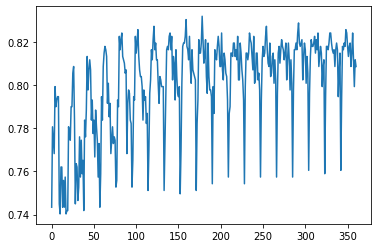

In [55]:
plt.plot(list(range(len(rf_scores))), rf_scores)
plt.show();

<div class="alert alert-warning">
<font size="5"><b>Комментарий ревьюераV2</b></font>

Совет:

Стоило построить трёхмерный график, или heatmap

</div>


Теперь исследуем модель случайного леса. Подберем налучшие значения для гиперпараметров n_estimators и max_depth. Здесь точность наиболее высокая - 0.83





<div class="alert alert-success">
<font size="5"><b>Комментарий ревьюера</b></font>

Успех:
    
По большему числу гиперпараметров перебор -   тем лучше метрика. Здорово   




<div class="alert alert-warning">


Совет: 

- Здорово что использован перебор не по одному гиперпараметру. Поэтому посоветую поизучать sklearn-ий GreedSearchCV. В случаи использования GridSearch, не нужно будет заранее делать валидационную выборку, лучшую метрику автоматом сохранят в best_score_, а лучшую модель (переобученная уже на полном наборе данных) будет хранить в best_estimator_. Это тема будущих теоретических занятий, но если есть время можешь сразу попробовать.

- Когда что то долго крутиться, можно использовать  %%time - ставишь на самый вверх ячейки с кодом, время выполнения которого хочешь замерить, может не знаешь.  Быстрее не станет, но все будут видеть стоит ли ждать не отходя от ПК или можно сходить чаек поставить ))  А еще есть tqdm, показывает на каком этапе у нас работа в цикле происходит


</div>


In [56]:
model = LogisticRegression(random_state=12345, solver='lbfgs', max_iter=1000)
model.fit(features_train, target_train)
result = model.score(features_valid, target_valid)
print(result)


0.7558320373250389


Посмотри на модель логистической регрессии. Здесь результаты тоже удовлетворительные, но для решения данной конкретной задачи такая модель не подходит.

Резюмируя, оптимальной моделью является случайны лес с гиперпараметрами max_depth равным 8 и n_estimators равным 10.


<div class="alert alert-success">
<font size="5"><b>Комментарий ревьюера</b></font>

Успех:


Все верно, RF лучший. 


<div class="alert alert-warning">


Совет: 

Если есть желание можешь ответить на вопросики ))    



- Как назвать ситуацию, когда на валидации при увеличении глубины дерева (модель DT), метрика качества стала снижаться? Как по твоему в это же время вела себя эта же метрика на train?


- Насколько знаю вы еще под капот моделям не заглядывали, но может знаешь почему RF показывает более высокие результаты из выбранных?


- Мы решаем задачу классификации (а еще есть задача регрессии), а в названии модели с помощью которой мы решаем задачу "классификации" есть слово "регрессия".  Нет ли тут парадокса? )
    

- Почему логистическая регрессия показывать на много более худшие результаты?  


</div>





переобучение

по сути, случайный лес состоит из нескольких решающих деревьев, а значит в целом среднее показателей этих деревьев будет наиболее близким к истине

Для оценки параметров уравнения логистической регрессии принято использовать метод максимального правдоподобия. Он заключается в подборе параметров таким образом, чтобы после подстановки данных в модель обеспечивалась максимальная вероятность осуществления события или принятия решения, которое соответствует данным. Регрессия указывает на определенную "формулу", по которой модель классифицирует объекты.

Данный метод не всегда может полностью отразить все взаимосвязи между переменными

<div class="alert alert-success">
<font size="5"><b>Комментарий ревьюераV2</b></font>


Успех:


Дополню чуть

1. Верно, переобучение. На train точность растет вплоть до 100%. 
    
    
2. Да, в RF обучается несколько деревьев, а решение принимается путем голосования. Каждое дерево в RF учится на своем датасете (используется техника бутстрап), таким образом достигается "независимость" этих самых деревьев, в итоге ошибка разброса снижается.

    
3. "Регрессия", потому что внутри нее скалярное произведение (как и в линейной регрессии), дающее на выходе вещественное число (от + бесконечности до - бесконечности), на это число вешают сигмойду, логарифм и получают значение от 0 до 1 (вероятность класса).   
    
    
4. Да, есть ограничения. Логистическая регрессия плоха (и хороша с другой стороны) тем что это линейный классификатор: обьекты на классы разделяем гиперплоскостью (прямой если на плоскости), а в данном датасете видимо более сложные, нелинейные связи между признаками и таргетом.   А RF с DT с этим справляются. На других данных  LR могла оказаться лучше, например потому что RF не может экстраполировать. 


</div>

## Проверьте модель на тестовой выборке

In [57]:
result = best_model_rf.score(features_test, target_test)
print(result)

0.8102643856920684


Для выбранной модели на тестовой выборке результаты также получились вполне удовлетворительными. Однако точность значительно варьирует.

In [58]:
new_rf_model = RandomForestClassifier(random_state=12345, n_estimators=10, max_depth=8)
new_rf_model.fit(features_train_valid, target_train_valid)
print(new_rf_model.score(features_test, target_test))

0.807153965785381



<div class="alert alert-success">
<font size="5"><b>Комментарий ревьюераV2</b></font>

Успех:

Попробовала но не получилось, бывает )
</div>


После обучения аналогичной модели на тренировочной + валидационной выборке качество немного ухудшилось, возможно, -  это следствие переобучения.

In [59]:
best_predictions = best_model_rf.predict(features_train)
print(precision_score(target_train, best_predictions))

0.9483695652173914



<div class="alert alert-success">
<font size="5"><b>Комментарий ревьюера</b></font>

Успех:


- Все верно, логика моделирования не нарушена, тут тестируем только лучшую модель (или парочку, если метрики были близки на валидации) отобранную на валидации. 

- Если студент получил на тесте accuraсy  выше 0,78, это считается отличным результатом. Ты подбирала лучшую комбинацию не по одному гиперпараметру и вот он результат!


<div class="alert alert-warning">

Вопросики и совет:




- Как попробовать улучшить результат, не мучаясь с кодом?! Смотри - мы сформировали train выборку на которой обучаем модель, а валидационную используем для поиска лучших значений гиперпараметров. Оке, нашли их. Так почему бы теперь модель с выбранными гиперпараметрами не обучить на тренировочной + валидационной выборке (только не нужно делать новые сплиты, используй pd.concat(), к примеру)?! Чем больше данных, тем лучше модель может обучиться. И эту дообученную модель проверим на тесте. Гаранитий что станет лучше нет, но ML это постоянные эксперименты.  
    
    
- А можешь предложить как нам использовать полученный результат в бизнесе? Как нам на этих прогнозах сделать деньги? 




- В качестве бонуса можешь вывести еще несколько метрик своей модели - precision, recall, F1 и confussion matrix) Все есть в sklearn)




</div>



## (бонус) Проверьте модели на адекватность

In [60]:
dummy_clf = DummyClassifier(strategy='stratified', random_state=12345)
dummy_clf.fit(features_train, target_train)
result_valid = dummy_clf.score(features_valid, target_valid)
result_test = dummy_clf.score(features_test, target_test)
print(result_valid, result_test)


0.5878693623639192 0.578538102643857


Для сравнения посмотрим на метрику accuracy для неточной, неподготовленной модели из класса DummyClassifier. Она различается примерно на 0,2 - значительно.

ВЫВОДЫ

В ходе исследования был использован большой датасет, который был разделен на тестовую, валидационную и обучающую выборки в соответствующем соотношении. Далее были изучены модели 3 разных классов - решающие дерево, случайный лес и логистическая регрессия с подбором наиболее оптимальных гиперпараметров. Была выбрана наиболее точная модель в соответствии с метрикой accuracy, после чего данные были проверены на вменяемость.

1. Наилучшей моделью для решения данной конкретно задачи можно считать случайнй лес. Здесь нам важнее точность, а не скорость.

2. Наиболее оптимальными гиперпараметрами для этой модели являются n_estimators - 10, max_depth - 8.

3. Метрика accuracy для этой модели состовляет около 0.83, что намного превышает то е значение для модели класса DummyClassifier.

<div class="alert alert-success">
<font size="5"><b>Комментарий ревьюера</b></font>

Успех:

 
- Все верно, здорово что используешь специальную обертку для проверки на адекватность


- здорово что в конце расписаны все этапы работы. Это важно потому что когда проект захочет посмотреть будущий работодатель (или начальник), у него может не быть времени на подробный разбор кода. Вероятнее всего он бегло просмотрит код, а из общего вывода захочет получить представление о всей работе.

    
</div>

## Чек-лист готовности проекта


<div class="alert alert-info">
<font size="5"><b>Комментарий ревьюера</b></font>


Мария ты старательно выполнила работу, все четко, осмысленно. Выводы присутствуют. Вижу у тебя получается в ML,  дальше будет интересней )  


Я оставил небольшие советы и вопросики (если есть время и желание можешь воспользоваться/ответить): 

- обрати внимание на проверку сбалансированность классов в таргете в разделе EDA
- использовать stratify
- добавить график метрики    
- посоветовал посмотреть в сторону GridSearchCV
- как можно улучшить результаты 

Замечания на будущее:
    
- Комментарии к коду отсутствуют - коллеги могут не понять хода твоих мыслей, пока вроде код простой, но стоит держать в голове что дальше код усложнится.  


 
    
Обязательное к исправлению:




- проект аналитический, поэтому минимальный EDA стоит сделать    


- лишний train_test_split

Жду исправлений, для принятия проекта. Если какие то вопросы, то сразу спрашивай ) 


</div>






<div class="alert alert-info">
<font size="5"><b>Комментарий ревьюераV2</b></font>



    
Красное исправлено, многие желтые советы использованы, на  вопросы есть ответы  (это все было по желанию), значит стремишься развиваться, а желание и интерес это главное. Надеюсь мои советы и вопросики были полезны и ты узналА что то новое, а проект стал лучше, и симпатичней.


Отличная работа Мария. Желаю успехов в дальнейшей учебе!






</div>

Поставьте 'x' в выполненных пунктах. Далее нажмите Shift+Enter.

- [x] Jupyter Notebook открыт
- [ ] Весь код исполняется без ошибок
- [ ] Ячейки с кодом расположены в порядке исполнения
- [ ] Выполнено задание 1: данные загружены и изучены
- [ ] Выполнено задание 2: данные разбиты на три выборки
- [ ] Выполнено задание 3: проведено исследование моделей
    - [ ] Рассмотрено больше одной модели
    - [ ] Рассмотрено хотя бы 3 значения гипепараметров для какой-нибудь модели
    - [ ] Написаны выводы по результатам исследования
- [ ] Выполнено задание 3: Проведено тестирование
- [ ] Удалось достичь accuracy не меньше 0.75
